In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
try:
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))
except ImportError:
    filename = "Housing.csv"  # Замініть назву за потреби

df = pd.read_csv(filename)
print("Розмір:", df.shape)
print("Стовпці:", df.columns.tolist())
display(df.head())

Saving Housing.csv to Housing.csv
Розмір: (545, 13)
Стовпці: ['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [3]:
required = ["area", "bathrooms", "bedrooms", "price"]
df.columns = df.columns.str.strip().str.lower()
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Не знайдено стовпці {missing}. Наявні: {df.columns.tolist()}")
data = df[required].apply(pd.to_numeric, errors="coerce").dropna()
X_raw = data[["area", "bathrooms", "bedrooms"]].to_numpy(dtype=float)
y_raw = data["price"].to_numpy(dtype=float)
m = len(y_raw)
X = np.column_stack([np.ones(m), X_raw])
print("Матриця X:", X.shape, "Вектор y:", y_raw.shape)

x_mean = X_raw.mean(axis=0)
x_std = X_raw.std(axis=0)
if np.any(x_std == 0):
    raise ValueError("Одна з ознак стала: неможливо стандартизувати її цим способом")
y_mean, y_std = y_raw.mean(), y_raw.std()
if y_std == 0:
    raise ValueError("Усі ціни однакові")
X_scaled = np.column_stack([np.ones(m), (X_raw - x_mean) / x_std])
y_scaled = (y_raw - y_mean) / y_std

Матриця X: (545, 4) Вектор y: (545,)


In [4]:
def hypothesis(X, w):
    return X @ w

print("Перші прогнози для нульових ваг:", hypothesis(X_scaled[:3], np.zeros(X_scaled.shape[1])))

Перші прогнози для нульових ваг: [0. 0. 0.]


In [5]:
def compute_cost(X, y, w):
    errors = hypothesis(X, w) - y
    return np.sum(errors ** 2) / (2 * len(y))

print("Початкова втрата:", compute_cost(X_scaled, y_scaled, np.zeros(X_scaled.shape[1])))

Початкова втрата: 0.4999999999999998


In [6]:
def gradient_step(X, y, w, learning_rate):
    gradient = (X.T @ (hypothesis(X, w) - y)) / len(y)
    return w - learning_rate * gradient

w0 = np.zeros(X_scaled.shape[1])
print("Після одного кроку:", gradient_step(X_scaled, y_scaled, w0, 0.1))

Після одного кроку: [1.68264994e-17 5.35997346e-02 5.17545339e-02 3.66494026e-02]


Параметри градієнтного спуску: [-1.73171608e+05  3.78762754e+02  1.38604950e+06  4.06820034e+05]
Фінальна втрата (стандартизована): 0.2564584666470618


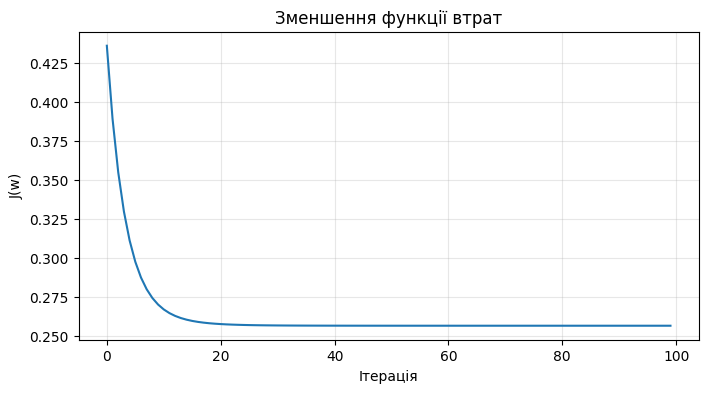

In [12]:
learning_rate = 0.1
iterations = 5000
w_scaled = np.zeros(X_scaled.shape[1])
history = []
for _ in range(iterations):
    w_scaled = gradient_step(X_scaled, y_scaled, w_scaled, learning_rate)
    history.append(compute_cost(X_scaled, y_scaled, w_scaled))

w_gd = np.empty_like(w_scaled)
w_gd[1:] = y_std * w_scaled[1:] / x_std
w_gd[0] = y_mean + y_std * w_scaled[0] - np.dot(w_gd[1:], x_mean)
print("Параметри градієнтного спуску:", w_gd)
print("Фінальна втрата (стандартизована):", history[-1])
plt.figure(figsize=(8, 4))
plt.plot(history[:100])
plt.xlabel("Ітерація")
plt.ylabel("J(w)")
plt.title("Зменшення функції втрат")
plt.grid(alpha=0.3)
plt.show()

In [8]:
w_analytic = np.linalg.pinv(X) @ y_raw
print("Аналітичні параметри:", w_analytic)

Аналітичні параметри: [-1.73171608e+05  3.78762754e+02  1.38604950e+06  4.06820034e+05]


In [9]:
model = LinearRegression()
model.fit(X_raw, y_raw)
w_sklearn = np.r_[model.intercept_, model.coef_]
print("Параметри sklearn:", w_sklearn)

Параметри sklearn: [-1.73171608e+05  3.78762754e+02  1.38604950e+06  4.06820034e+05]


In [10]:
comparison = pd.DataFrame({
    "Параметр": ["w0 (вільний член)", "w1 (площа)", "w2 (ванні кімнати)", "w3 (спальні)"],
    "Градієнтний спуск": w_gd,
    "Аналітичний метод": w_analytic,
    "scikit-learn": w_sklearn,
})
display(comparison)

predictions = {
    "Градієнтний спуск": hypothesis(X, w_gd),
    "Аналітичний метод": hypothesis(X, w_analytic),
    "scikit-learn": model.predict(X_raw),
}
metrics = []
for name, pred in predictions.items():
    metrics.append({
        "Метод": name,
        "MAE": mean_absolute_error(y_raw, pred),
        "MSE": mean_squared_error(y_raw, pred),
        "R²": r2_score(y_raw, pred),
    })
display(pd.DataFrame(metrics))

display(pd.DataFrame({"Фактична ціна": y_raw[:10], **{k: v[:10] for k, v in predictions.items()}}))
print("Макс. різниця прогнозів GD та sklearn:", np.max(np.abs(predictions["Градієнтний спуск"] - predictions["scikit-learn"])))
print("Макс. різниця прогнозів аналітичного методу та sklearn:", np.max(np.abs(predictions["Аналітичний метод"] - predictions["scikit-learn"])))

,Параметр,Градієнтний спуск,Аналітичний метод,scikit-learn
0,w0 (вільний член),-1.731716e+05,-1.731716e+05,-1.731716e+05
1,w1 (площа),3.787628e+02,3.787628e+02,3.787628e+02
2,w2 (ванні кімнати),1.386049e+06,1.386049e+06,1.386049e+06
3,w3 (спальні),4.068200e+05,4.068200e+05,4.068200e+05


,Метод,MAE,MSE,R²
0,Градієнтний спуск,999109.724595,1.791170e+12,0.487083
1,Аналітичний метод,999109.724595,1.791170e+12,0.487083
2,scikit-learn,999109.724595,1.791170e+12,0.487083


,Фактична ціна,Градієнтний спуск,Аналітичний метод,scikit-learn
0,13300000.0,7.036627e+06,7.036627e+06,7.036627e+06
1,12250000.0,1.039202e+07,1.039202e+07,1.039202e+07
2,12250000.0,7.591865e+06,7.591865e+06,7.591865e+06
3,12215000.0,7.066928e+06,7.066928e+06,7.066928e+06
4,11410000.0,5.650578e+06,5.650578e+06,5.650578e+06
5,10850000.0,8.046158e+06,8.046158e+06,8.046158e+06
6,10150000.0,8.862041e+06,8.862041e+06,8.862041e+06
7,10150000.0,1.215503e+07,1.215503e+07,1.215503e+07
8,9870000.0,5.908136e+06,5.908136e+06,5.908136e+06
9,9800000.0,5.997273e+06,5.997273e+06,5.997273e+06


Макс. різниця прогнозів GD та sklearn: 1.0244548320770264e-08
Макс. різниця прогнозів аналітичного методу та sklearn: 4.0978193283081055e-08


## 10. Візуалізація фактичних і прогнозованих цін

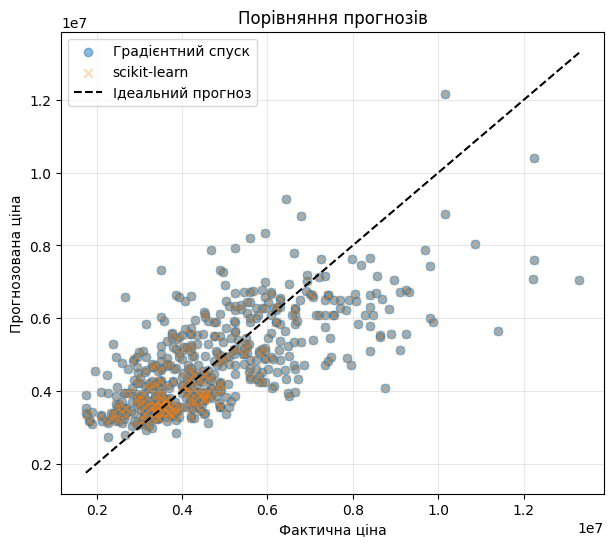

In [11]:
plt.figure(figsize=(7, 6))
plt.scatter(y_raw, predictions["Градієнтний спуск"], alpha=0.5, label="Градієнтний спуск")
plt.scatter(y_raw, predictions["scikit-learn"], alpha=0.3, marker="x", label="scikit-learn")
low = min(y_raw.min(), *(v.min() for v in predictions.values()))
high = max(y_raw.max(), *(v.max() for v in predictions.values()))
plt.plot([low, high], [low, high], "k--", label="Ідеальний прогноз")
plt.xlabel("Фактична ціна")
plt.ylabel("Прогнозована ціна")
plt.title("Порівняння прогнозів")
plt.legend()
plt.grid(alpha=0.3)
plt.show()